# Week 12A: Census analysis with DuckDB Spatial

Create a database, query Census point data with Python and SQL, ask spatial questions, and export maps for a website.

<a href="lecture-12A.ipynb" download>Download notebook</a> · [Next: Quarto, ChatGPT, and GitHub Pages](lecture-12B.html)

## 1. What is a database?

A database stores organized data and lets us ask questions without rewriting files by hand. A **table** has rows (records) and columns (attributes). A **schema** describes column names and types. A **primary key** uniquely identifies a record. A **query** selects or summarizes records; **SQL** is the language we use here.

| File / tool | Main role in this lab |
| --- | --- |
| Parquet / GeoJSON | Downloadable source files |
| DuckDB `.duckdb` file | Persistent database with tables, views, and geometry |
| Python | Open connections, send SQL, inspect results, and plot |
| CSV / GeoJSON / PNG | Small exports we can publish on a static website |

DuckDB runs inside Python and stores this database in one file. It is convenient for local analytical work. A shared application with many writers would normally use a server database instead. Its **Spatial** extension adds geometry types and spatial functions. [DuckDB Python documentation](https://duckdb.org/docs/1.5/clients/python/overview) · [Spatial extension](https://duckdb.org/docs/1.5/core_extensions/spatial/overview).

## 2. Reuse your Week 11 data and prepare Python

**No new Census data download is needed.** Use the same `census_sample.parquet` and `districts_2015.geojson` files from Week 11. Save this notebook and <a href="environment.yml" download>environment.yml</a> in a new `week12` folder next to your `week11` folder:

```text
course-work/
├── week11/
│   └── data/samples/
│       ├── census_sample.parquet
│       └── districts_2015.geojson
└── week12/
    ├── lecture-12A.ipynb
    └── environment.yml
```

Open the notebook from `week12`. `DATA = Path("../week11/data/samples")` below points to your existing files. If you used another folder name, edit that one path. The point file is the previous week's systematically thinned **synthetic 2010 Census dot extract**; the polygons are historical 2015 congressional boundaries. We select Pennsylvania inside DuckDB. Counts are **sample dots, not population estimates or current district demographics**. [Original data provenance](../week11-large-data-viz-lidar/data/samples/provenance.json).

Open a terminal in `week12`:

```bash
conda env create -f environment.yml
conda activate census-web
python -m ipykernel install --user --name census-web --display-name "Python (census-web)"
jupyter lab
```

Select **Python (census-web)**. Quarto is installed separately for the next section. For an existing environment, use `conda env update -n census-web -f environment.yml` instead.


In [1]:
from pathlib import Path
import duckdb
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

DATA = Path("../week11/data/samples")
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
print("DuckDB:", duckdb.__version__)

DuckDB: 1.5.6


## 3. Create and connect to a database

`connect()` creates the file if it does not exist, or opens it if it does. `:memory:` would create a temporary database instead. This file stays local; the website will use small exports, not a live connection to this Python session.

`INSTALL spatial` downloads the extension the first time and needs internet access. `LOAD spatial` activates it in each new connection. If installation fails, check the network and use the DuckDB version in `environment.yml`. [Extension documentation](https://duckdb.org/docs/1.5/core_extensions/spatial/overview).

In [2]:
database_path = OUT / "census_tutorial.duckdb"
con = duckdb.connect(str(database_path))
con.execute("INSTALL spatial")
con.execute("LOAD spatial")
con.execute("SELECT 2 + 3 AS first_query").df()

,first_query
0,5


## 4. Create tables and import source files

We will make two tables: `census_points` and `districts`. Their ID columns are primary keys. The next two cells **rebuild these demonstration tables** on rerun; use this tutorial database, not a shared database with other work.

First import Pennsylvania polygons, then keep only Census points they cover. A coarse coordinate filter reduces the first scan; the final `ST_Covers` test defines the selection precisely.

The point source uses EPSG:3857, and the boundary GeoJSON uses longitude/latitude, EPSG:4326. Transform both to **EPSG:26918 (UTM zone 18N, meters)** for local spatial operations. `always_xy := true` makes longitude/X the first axis. Do not measure distances directly in longitude/latitude degrees. A geometry column does not relieve us of tracking its CRS. [Spatial functions](https://duckdb.org/docs/1.5/core_extensions/spatial/functions).

In [3]:
con.execute("""
    CREATE OR REPLACE TABLE districts (
        district_id VARCHAR PRIMARY KEY,
        geom GEOMETRY
    )
""")
con.execute("""
    INSERT INTO districts
    SELECT STATEFP || CD114FP AS district_id,
           ST_Transform(geom, 'EPSG:4326', 'EPSG:26918', always_xy := true)
    FROM ST_Read(?)
    WHERE STATEFP = '42'
""", [str(DATA / "districts_2015.geojson")])
con.execute("SHOW TABLES").df()

,name
0,districts


In [4]:
con.execute("""
    CREATE OR REPLACE TABLE census_points (
        point_id INTEGER PRIMARY KEY,
        category VARCHAR,
        geom GEOMETRY
    )
""")
con.execute("""
    INSERT INTO census_points
    WITH candidates AS (
        SELECT easting AS x, northing AS y, race::VARCHAR AS category,
               ST_Transform(ST_Point(easting, northing), 'EPSG:3857', 'EPSG:26918', always_xy := true) AS geom
        FROM read_parquet(?)
        WHERE easting BETWEEN -9000000 AND -8200000
          AND northing BETWEEN 4750000 AND 5300000
    )
    SELECT row_number() OVER (ORDER BY p.x, p.y, p.category), p.category, p.geom
    FROM candidates p
    WHERE EXISTS (SELECT 1 FROM districts d WHERE ST_Covers(d.geom, p.geom))
""", [str(DATA / "census_sample.parquet")])
con.execute("SELECT point_id, category, ST_AsText(geom) AS coordinates FROM census_points LIMIT 5").df()

,point_id,category,coordinates
0,1,w,POINT (37508.231711089786 4580881.17369423)
1,2,w,POINT (37476.98586446396 4580105.704547788)
2,3,w,POINT (31695.953387025045 4488475.852722617)
3,4,w,POINT (35015.90324350167 4541065.591734792)
4,5,w,POINT (37381.941080673656 4578292.468608493)


### Inspect the schema and data quality

Check counts, unique IDs, empty or invalid geometry, and categories before analysis. `df()` returns the small query result as a pandas DataFrame; it need not load the whole source table.

In [5]:
display(con.execute("DESCRIBE census_points").df())
display(con.execute("""
    SELECT count(*) AS sample_dots,
           count(DISTINCT point_id) AS unique_ids,
           count(*) FILTER (WHERE geom IS NULL OR ST_IsEmpty(geom)) AS missing_geometry
    FROM census_points
""").df())
con.execute("SELECT count(*) AS districts, bool_and(ST_IsValid(geom)) AS all_valid FROM districts").df()

,column_name,column_type,null,key,default,extra
0,point_id,INTEGER,NO,PRI,None,None
1,category,VARCHAR,YES,None,None,None
2,geom,GEOMETRY,YES,None,None,None


,sample_dots,unique_ids,missing_geometry
0,63552,63552,0


,districts,all_valid
0,18,True


## 5. Select, filter, sort, and summarize with SQL

`SELECT` chooses columns; `WHERE` filters rows; `GROUP BY` forms groups; `ORDER BY` sorts; `LIMIT` keeps a small result. `?` is a parameter placeholder: pass Python values separately instead of inserting user text into SQL strings.

In [6]:
category = "b"
con.execute("""
    SELECT point_id, category
    FROM census_points
    WHERE category = ?
    ORDER BY point_id
    LIMIT 5
""", [category]).df()

,point_id,category
0,23,b
1,34,b
2,36,b
3,38,b
4,50,b


In [7]:
con.execute("""
    CREATE OR REPLACE VIEW category_summary AS
    SELECT category, count(*) AS sample_dots,
           round(100.0 * count(*) / (SELECT count(*) FROM census_points), 2) AS sample_percent
    FROM census_points
    GROUP BY category
""")
category_counts = con.execute("SELECT * FROM category_summary ORDER BY sample_dots DESC").df()
category_counts

,category,sample_dots,sample_percent
0,w,50564,79.56
1,b,6653,10.47
2,h,3629,5.71
3,a,1683,2.65
4,o,1023,1.61


A **view** stores a query definition rather than another copy of the result. Here it updates automatically when the underlying teaching table changes.

### Visualize the query result

Use a bar chart for counts. The source categories are White (`w`), Black (`b`), Asian (`a`), Hispanic (`h`), and Other (`o`). They are source-specific historical categories, not an exhaustive description of identity.

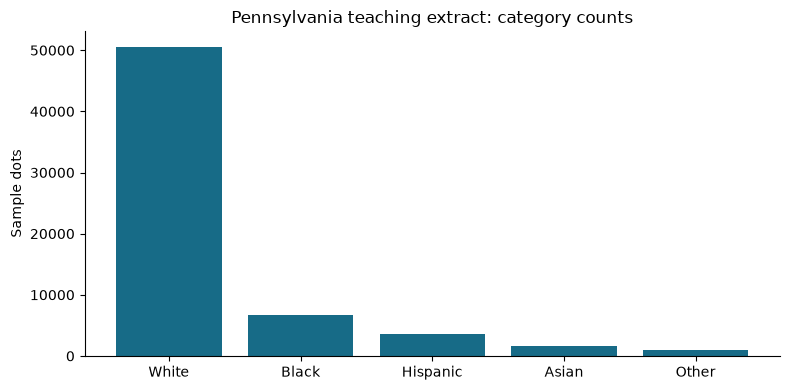

In [8]:
labels = {"w": "White", "b": "Black", "a": "Asian", "h": "Hispanic", "o": "Other"}
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(category_counts["category"].map(labels), category_counts["sample_dots"], color="#176b87")
ax.set(ylabel="Sample dots", title="Pennsylvania teaching extract: category counts")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / "category_counts.png", dpi=160)
plt.show()

## 6. Ask a spatial question: which district contains a location?

A spatial predicate compares geometries. `ST_Covers(polygon, point)` includes a polygon boundary; `ST_Contains` excludes boundary-only points. Transform the test point from longitude/latitude into the same CRS as the districts. This example uses Philadelphia City Hall.

In [9]:
longitude, latitude = -75.1636, 39.9526
con.execute("""
    WITH location AS (
        SELECT ST_Transform(ST_Point(?, ?), 'EPSG:4326', 'EPSG:26918', always_xy := true) AS geom
    )
    SELECT d.district_id
    FROM districts d, location p
    WHERE ST_Covers(d.geom, p.geom)
""", [longitude, latitude]).df()

,district_id
0,4201


### Find sample dots within 2 km

`ST_DWithin()` uses the units of our projected CRS: meters. It counts points from the extract, not people actually living within the circle. Change `radius_m` and compare the result.

In [10]:
radius_m = 2000
nearby_counts = con.execute("""
    WITH location AS (
        SELECT ST_Transform(ST_Point(?, ?), 'EPSG:4326', 'EPSG:26918', always_xy := true) AS geom
    )
    SELECT p.category, count(*) AS sample_dots
    FROM census_points p, location c
    WHERE ST_DWithin(p.geom, c.geom, ?)
    GROUP BY p.category
    ORDER BY sample_dots DESC
""", [longitude, latitude, radius_m]).df()
nearby_counts

,category,sample_dots
0,w,341
1,b,94
2,a,57
3,h,32
4,o,8


## 7. Spatial join: summarize dots by district

A spatial join matches rows by location instead of an ID. Points on a shared boundary could match more than one polygon. We assign those points once, to the smallest matching district ID, so our totals do not double count. This is a reproducible teaching rule, not a demographic allocation method.

In [11]:
con.execute("""
    CREATE OR REPLACE VIEW point_district AS
    SELECT p.point_id, min(d.district_id) AS district_id
    FROM census_points p
    JOIN districts d ON ST_Covers(d.geom, p.geom)
    GROUP BY p.point_id
""")
con.execute("""
    CREATE OR REPLACE VIEW district_summary AS
    SELECT d.district_id, count(a.point_id) AS sample_dots
    FROM districts d
    LEFT JOIN point_district a ON d.district_id = a.district_id
    GROUP BY d.district_id
""")
district_counts = con.execute("SELECT * FROM district_summary ORDER BY district_id").df()
district_counts

,district_id,sample_dots
0,4201,3466
1,4202,2661
2,4203,3581
3,4204,3539
4,4205,3448
5,4206,3599
6,4207,4008
7,4208,3617
8,4209,3518
9,4210,3473


In [12]:
point_count = con.execute("SELECT count(*) FROM census_points").fetchone()[0]
assigned_count = con.execute("SELECT count(*) FROM point_district").fetchone()[0]
assert point_count == assigned_count == int(district_counts["sample_dots"].sum())
print(f"All {point_count:,} sample dots assigned once across {len(district_counts)} districts.")

All 63,552 sample dots assigned once across 18 districts.


### What about spatial indexes?

An R-tree index can help some supported spatial filters on larger data. This small example does not need one, and not every query uses the index. Use `EXPLAIN` and measure performance before claiming a speedup. [DuckDB spatial indexes](https://duckdb.org/docs/1.5/core_extensions/spatial/r-tree_indexes).

In [13]:
con.execute("CREATE INDEX IF NOT EXISTS district_geom_idx ON districts USING RTREE (geom)")
print("Created an optional R-tree index on district geometry.")

Created an optional R-tree index on district geometry.


## 8. Map the analysis result

Return geometry as WKB (well-known binary) to create a GeoDataFrame. Tell GeoPandas the actual CRS; assigning a CRS does not transform coordinates. The map colors are **counts of sample dots**, not density or current population.

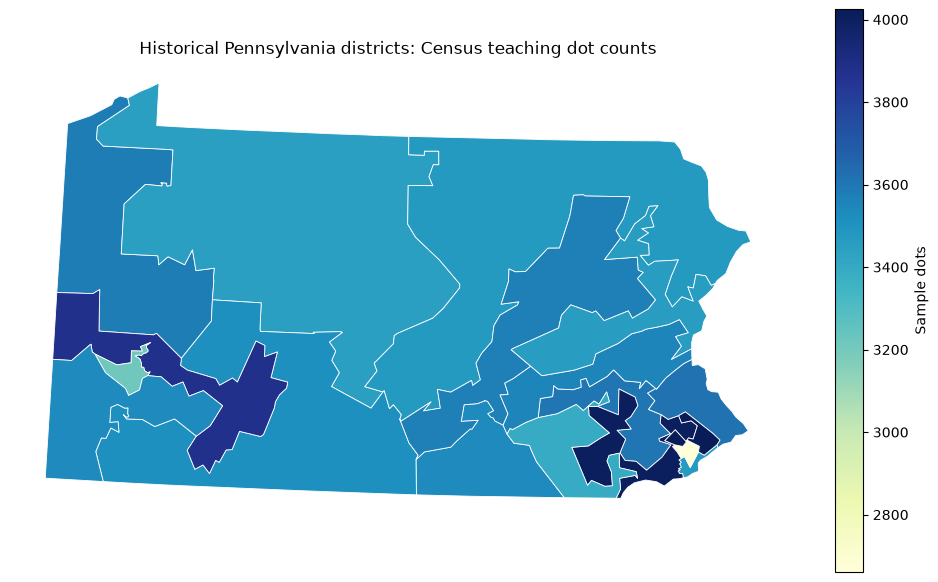

In [14]:
map_table = con.execute("""
    SELECT d.district_id, s.sample_dots, ST_AsWKB(d.geom) AS geometry_wkb
    FROM districts d JOIN district_summary s USING (district_id)
    ORDER BY district_id
""").df()
geometry = gpd.GeoSeries.from_wkb(map_table.pop("geometry_wkb").map(bytes), crs="EPSG:26918")
district_map = gpd.GeoDataFrame(map_table, geometry=geometry)
fig, ax = plt.subplots(figsize=(10, 6))
district_map.plot(column="sample_dots", cmap="YlGnBu", edgecolor="white", linewidth=0.6,
                  legend=True, legend_kwds={"label": "Sample dots"}, ax=ax)
ax.set(title="Historical Pennsylvania districts: Census teaching dot counts")
ax.set_axis_off()
fig.tight_layout()
fig.savefig(OUT / "district_sample_map.png", dpi=160)
plt.show()

## 9. Export small files for the website

Static websites can show exported tables, charts, and GeoJSON without starting Python or opening the DuckDB database. CSV keeps IDs as text only if the reader preserves them. GeoJSON is exported in longitude/latitude for web mapping.

In [15]:
category_counts.to_csv(OUT / "category_counts.csv", index=False)
category_counts.to_json(OUT / "category_counts.json", orient="records", indent=2)
district_counts.to_csv(OUT / "district_counts.csv", index=False)
district_map.to_crs("EPSG:4326").to_file(OUT / "district_sample.geojson", driver="GeoJSON")
print("Exports saved in outputs/.")

Exports saved in outputs/.


## 10. Close and reopen the database

Closing the connection does not delete the database file. Reopen in read-only mode to check persistence. Load Spatial again before working with geometries. Close connections before sharing the file; this is not a web server.

In [16]:
con.close()
with duckdb.connect(str(database_path), read_only=True) as saved:
    saved.execute("LOAD spatial")
    restored_count = saved.execute("SELECT count(*) FROM census_points").fetchone()[0]
assert restored_count == point_count
print("Reopened database:", database_path, "| sample dots:", restored_count)

Reopened database: outputs/census_tutorial.duckdb | sample dots: 63552


## Try it yourself

1. Filter two source categories with `WHERE category IN (...)` and group by category.
2. Change the search location and compare 1 km, 2 km, and 5 km radii.
3. Join category values to district assignments and count each category by district.
4. Explain why a sample-dot count is not a population estimate or a density.
5. Publish a map and a short explanation of the method in the next section.

**Outputs:** local `outputs/census_tutorial.duckdb`, CSV/JSON summaries, GeoJSON, and two PNG charts. Keep the database local; publish the small exports.

**Next:** [Quarto, ChatGPT, and GitHub Pages](lecture-12B.html).